In [38]:
import sys, torch
print(sys.executable)
print(torch.__version__)

/Users/nassimsellal/Documents/Mastère Big Data & IA/M1/Projets/FinancePred/venv/bin/python
2.15.0


In [39]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import warnings
warnings.filterwarnings("ignore", module="yfinance")   # avertissements internes à yfinance, hors de notre contrôle

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [40]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [41]:
ticker = "AMZN"
date = "2020-01-01"
end_date = "2026-11-01"       # date de fin fixe : les données ne bougeront plus
torch.manual_seed(42)

df = yf.download(ticker, start=date, end=end_date)


[*********************100%***********************]  1 of 1 completed


In [42]:
df

Price,Close,High,Low,Open,Volume
Ticker,AMZN,AMZN,AMZN,AMZN,AMZN
Date,,,,,
2020-01-02,94.900497,94.900497,93.207497,93.750000,80580000
2020-01-03,93.748497,94.309998,93.224998,93.224998,75288000
2020-01-06,95.143997,95.184502,93.000000,93.000000,81236000
2020-01-07,95.343002,95.694504,94.601997,95.224998,80898000
2020-01-08,94.598503,95.550003,94.321999,94.902000,70160000
...,...,...,...,...,...
2026-10-26,249.089996,250.789993,247.229996,249.470001,32696400
2026-10-27,253.100006,254.679993,248.710007,250.429993,34477800


<Axes: xlabel='Date'>

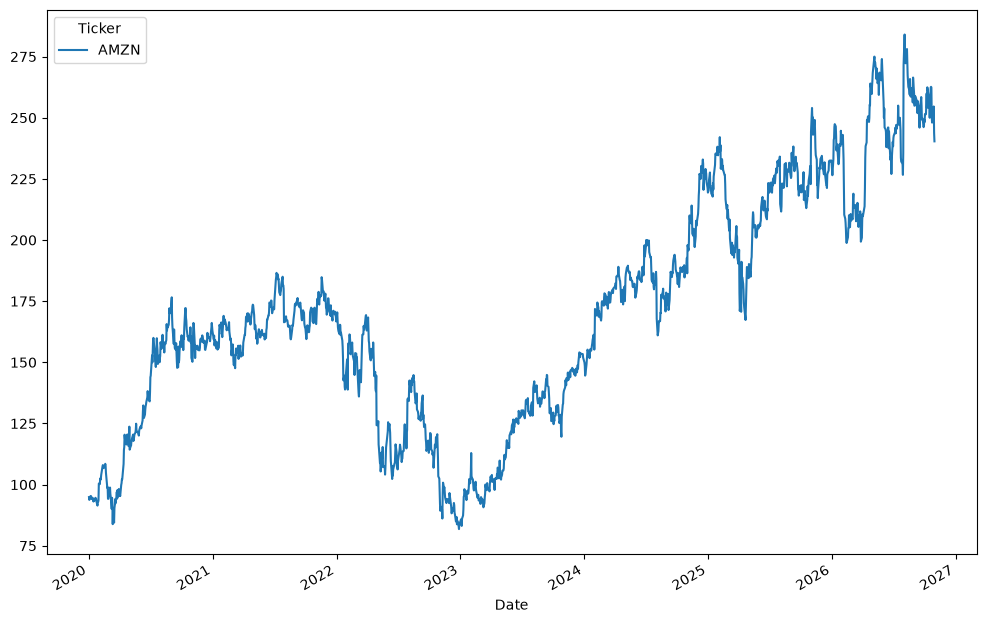

In [43]:
 df.Close.plot(figsize=(12,8))

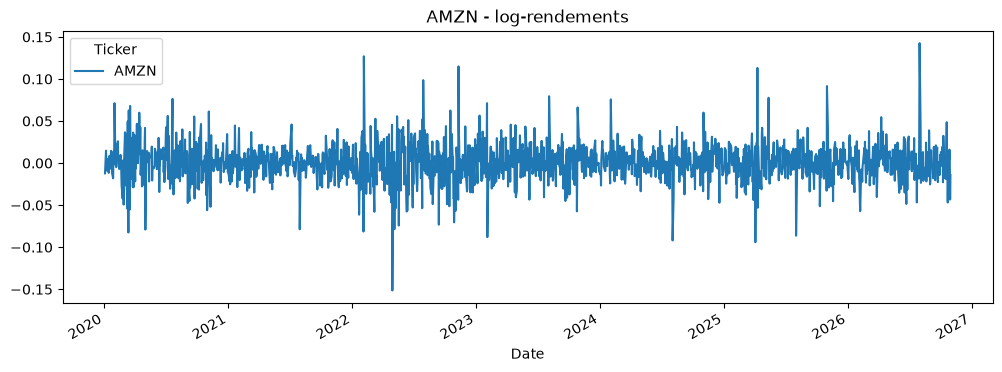

In [44]:
df['Close'] = np.log(df['Close']).diff()   # remplace le prix par le log-rendement
df = df.dropna()                            # le 1er jour n'a pas de veille -> NaN
df.Close.plot(figsize=(12, 4), title=f"{ticker} - log-rendements");

In [45]:
seq_length = 30
train_size = int(0.8 * (len(df) - seq_length))   # même valeur qu'avant
n_train_rows = train_size + seq_length - 1       # lignes couvertes par les fenêtres de train

scaler = StandardScaler()
scaler.fit(df['Close'].iloc[:n_train_rows])      # moyenne et écart-type du train SEUL
df['Close'] = scaler.transform(df['Close'])      # appliqués ensuite à toute la série

In [46]:
df.Close

Ticker,AMZN
Date,
2020-01-03,-0.563170
2020-01-06,0.622962
2020-01-07,0.065413
2020-01-08,-0.370939
2020-01-09,0.183997
...,...
2026-10-26,0.166322
2026-10-27,0.675460
2026-10-28,0.233278


In [47]:
data = []
for i in range (len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])
data= np.array(data)

In [48]:
data

array([[[-0.56317005],
        [ 0.62296152],
        [ 0.06541297],
        ...,
        [ 0.16117264],
        [-0.23300919],
        [-0.33412442]],

       [[ 0.62296152],
        [ 0.06541297],
        [-0.37093855],
        ...,
        [-0.23300919],
        [-0.33412442],
        [ 0.39970199]],

       [[ 0.06541297],
        [-0.37093855],
        [ 0.18399716],
        ...,
        [-0.33412442],
        [ 0.39970199],
        [ 0.26922532]],

       ...,

       [[-0.46378478],
        [ 0.89829013],
        [ 0.4122906 ],
        ...,
        [-0.44616722],
        [ 0.16632202],
        [ 0.67546044]],

       [[ 0.89829013],
        [ 0.4122906 ],
        [ 0.78708765],
        ...,
        [ 0.16632202],
        [ 0.67546044],
        [ 0.23327751]],

       [[ 0.4122906 ],
        [ 0.78708765],
        [-0.62047395],
        ...,
        [ 0.67546044],
        [ 0.23327751],
        [-1.93318342]]], shape=(1686, 30, 1))

In [49]:
x_train=torch.from_numpy(data[:train_size, :-1,:]).type(torch.Tensor).to(device)
y_train=torch.from_numpy(data[:train_size, -1,:]).type(torch.Tensor).to(device)
x_test=torch.from_numpy(data[train_size:, :-1,:]).type(torch.Tensor).to(device)
y_test=torch.from_numpy(data[train_size:, -1,:]).type(torch.Tensor).to(device)

In [50]:
val_size = int(0.2 * len(x_train))      # les 20 % les plus récents du train
x_tr, y_tr = x_train[:-val_size], y_train[:-val_size]
x_val, y_val = x_train[-val_size:], y_train[-val_size:]

In [51]:
x_train

tensor([[[-0.5632],
         [ 0.6230],
         [ 0.0654],
         ...,
         [ 0.3201],
         [ 0.1612],
         [-0.2330]],

        [[ 0.6230],
         [ 0.0654],
         [-0.3709],
         ...,
         [ 0.1612],
         [-0.2330],
         [-0.3341]],

        [[ 0.0654],
         [-0.3709],
         [ 0.1840],
         ...,
         [-0.2330],
         [-0.3341],
         [ 0.3997]],

        ...,

        [[ 3.3844],
         [ 0.5449],
         [-0.2599],
         ...,
         [-0.4995],
         [-0.6156],
         [-0.2829]],

        [[ 0.5449],
         [-0.2599],
         [-1.1013],
         ...,
         [-0.6156],
         [-0.2829],
         [ 0.8709]],

        [[-0.2599],
         [-1.1013],
         [ 0.0635],
         ...,
         [-0.2829],
         [ 0.8709],
         [-0.1878]]])

In [52]:
y_train

tensor([[-0.3341],
        [ 0.3997],
        [ 0.2692],
        ...,
        [ 0.8709],
        [-0.1878],
        [ 1.0244]])

In [53]:
class PredictionModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel,self).__init__()
        
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)
    
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out=self.fc(out[:,-1,:])
        return out

In [54]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [55]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(),lr=0.01)

In [56]:
import copy

num_epochs = 200
best_val, best_state, patience, wait = float('inf'), None, 20, 0

for i in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(x_tr), y_tr)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(x_val), y_val).item()

    if val_loss < best_val:              # nouveau meilleur modèle : on le sauvegarde
        best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= patience:             # 20 époques sans progrès : on arrête
            print(f"Arrêt anticipé à l'époque {i}")
            break

    if i % 25 == 0:
        print(f"{i:3d} | train {loss.item():.4f} | val {val_loss:.4f}")

model.load_state_dict(best_state)        # on revient à la meilleure version

  0 | train 1.0444 | val 0.8953
 25 | train 1.0387 | val 0.8816
Arrêt anticipé à l'époque 27


<All keys matched successfully>

In [57]:
model.eval()
with torch.no_grad():
    y_train_pred = model(x_train)
    y_test_pred = model(x_test)

# nouveaux noms : les tenseurs y_train / y_test restent intacts
y_train_pred = scaler.inverse_transform(y_train_pred.cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.cpu().numpy())
y_train_true = scaler.inverse_transform(y_train.cpu().numpy())
y_test_true = scaler.inverse_transform(y_test.cpu().numpy())

In [58]:
train_rmse = root_mean_squared_error(y_train_true[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test_true[:, 0], y_test_pred[:, 0])

In [59]:
train_rmse

0.022859176620841026

In [60]:
test_rmse

0.020733589306473732

In [61]:
zero_pred = np.zeros_like(y_test_true)                  # baseline : rendement nul
zero_rmse = root_mean_squared_error(y_test_true[:, 0], zero_pred[:, 0])

def direction_acc(y_true, y_pred):
    return np.mean((y_true > 0) == (y_pred > 0))   # % de bon sens hausse/baisse

print(f"RMSE LSTM : {test_rmse:.5f}")
print(f"RMSE zéro : {zero_rmse:.5f}")
print(f"Direction LSTM : {direction_acc(y_test_true, y_test_pred):.1%}")
print(f"Direction 'toujours hausse' : {np.mean(y_test_true > 0):.1%}")

RMSE LSTM : 0.02073
RMSE zéro : 0.02073
Direction LSTM : 52.1%
Direction 'toujours hausse' : 51.8%


In [62]:
from sklearn.linear_model import LinearRegression

# sklearn attend des tableaux 2D (n_exemples, n_variables) : on retire la 3e dimension
X_lin_train = x_train.cpu().numpy()[:, :, 0]
X_lin_test = x_test.cpu().numpy()[:, :, 0]

lin = LinearRegression().fit(X_lin_train, y_train.cpu().numpy())
lin_pred = scaler.inverse_transform(lin.predict(X_lin_test))

mean_pred = np.full_like(y_test_true, y_train_true.mean())

def rmse(pred):
    return root_mean_squared_error(y_test_true[:, 0], pred[:, 0])

results = pd.DataFrame({
    "Modèle": ["Zéro", "Moyenne train", "Régression linéaire", "LSTM"],
    "RMSE": [rmse(zero_pred), rmse(mean_pred), rmse(lin_pred), rmse(y_test_pred)],
    "Direction": [np.nan,                       # prédire 0 ne donne aucun sens
                  direction_acc(y_test_true, mean_pred),
                  direction_acc(y_test_true, lin_pred),
                  direction_acc(y_test_true, y_test_pred)],
})
results.round(5)

,Modèle,RMSE,Direction
0,Zéro,0.02073,NaN
1,Moyenne train,0.02072,0.51775
2,Régression linéaire,0.02084,0.50000
3,LSTM,0.02073,0.52071


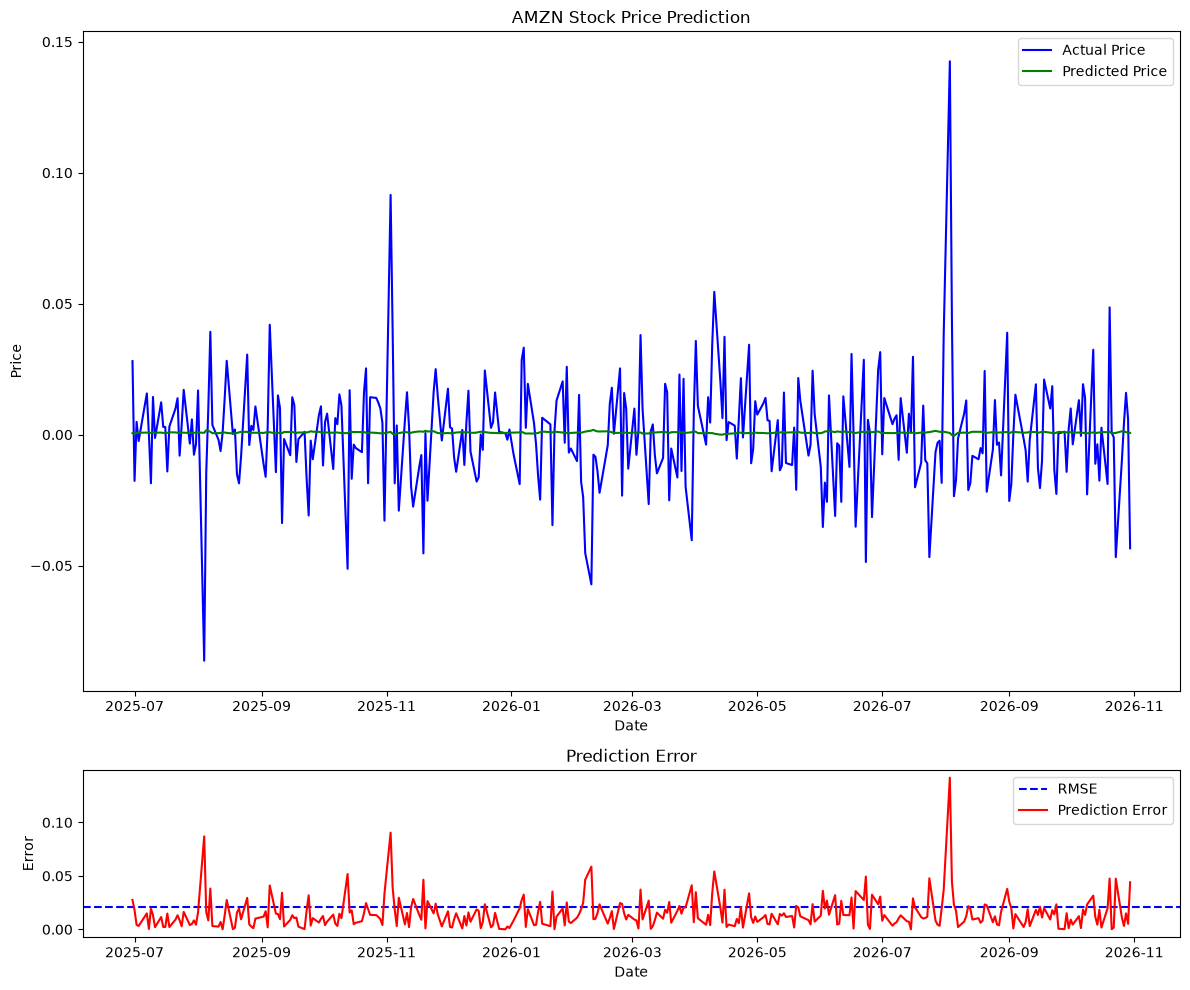

In [63]:
fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(4, 1)
axl = fig.add_subplot(gs[:3, 0])
axl.plot(df.iloc[-len(y_test_true):].index, y_test_true, color = 'blue', label = 'Actual Price')
axl.plot(df.iloc[-len(y_test_true):].index, y_test_pred, color = 'green', label = 'Predicted Price')
axl.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel('Date')
plt.ylabel('Price')
ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = 'blue', linestyle = '--', label = 'RMSE')
ax2.plot(df.iloc[-len(y_test_true):].index, np.abs(y_test_true - y_test_pred), 'r', label = 'Prediction Error')
ax2.legend()
plt.title('Prediction Error')
plt.xlabel('Date')
plt.ylabel('Error')
plt.tight_layout()

plt.show()

In [64]:
%load_ext autoreload
%autoreload 2
from benchmark import run_benchmark

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [65]:
tickers = ["AMZN", "AAPL", "MSFT", "JPM", "KO", "MC.PA", "^GSPC"]

rows = []
for t in tickers:
    print(f"{t}...")
    try:
        rows.append(run_benchmark(t))
    except Exception as e:
        print(f"  {t} ignoré : {e}")

results_all = pd.DataFrame(rows).set_index("Ticker")
results_all.round(4)

AMZN...
AAPL...
MSFT...
JPM...
KO...
MC.PA...
^GSPC...


,Jours test,RMSE zéro,RMSE moyenne,RMSE linéaire,RMSE LSTM,LSTM vs zéro (%),Dir. toujours hausse,Dir. linéaire,Dir. LSTM,Époque d'arrêt
Ticker,,,,,,,,,,
AMZN,338,0.0207,0.0207,0.0208,0.0207,0.0383,0.5178,0.5000,0.5207,27
AAPL,338,0.0153,0.0152,0.0155,0.0153,-0.0620,0.5414,0.4763,0.5118,42
MSFT,338,0.0183,0.0184,0.0193,0.0184,0.1269,0.5030,0.5148,0.4941,21
JPM,338,0.0133,0.0133,0.0139,0.0134,0.6850,0.5562,0.4852,0.5592,47
KO,338,0.0114,0.0113,0.0116,0.0113,-0.3269,0.5059,0.4911,0.5030,62
MC.PA,344,0.0186,0.0186,0.0189,0.0187,0.4772,0.4651,0.4738,0.5349,20
^GSPC,338,0.0076,0.0076,0.0079,0.0076,0.1491,0.5444,0.5000,0.5207,59


In [66]:
results_all.iloc[:, :6].round(4)   # les RMSE

,Jours test,RMSE zéro,RMSE moyenne,RMSE linéaire,RMSE LSTM,LSTM vs zéro (%)
Ticker,,,,,,
AMZN,338,0.0207,0.0207,0.0208,0.0207,0.0383
AAPL,338,0.0153,0.0152,0.0155,0.0153,-0.0620
MSFT,338,0.0183,0.0184,0.0193,0.0184,0.1269
JPM,338,0.0133,0.0133,0.0139,0.0134,0.6850
KO,338,0.0114,0.0113,0.0116,0.0113,-0.3269
MC.PA,344,0.0186,0.0186,0.0189,0.0187,0.4772
^GSPC,338,0.0076,0.0076,0.0079,0.0076,0.1491


In [67]:
results_all.iloc[:, 6:].round(4)   # l'écart, les directions et l'époque d'arrêt

,Dir. toujours hausse,Dir. linéaire,Dir. LSTM,Époque d'arrêt
Ticker,,,,
AMZN,0.5178,0.5000,0.5207,27
AAPL,0.5414,0.4763,0.5118,42
MSFT,0.5030,0.5148,0.4941,21
JPM,0.5562,0.4852,0.5592,47
KO,0.5059,0.4911,0.5030,62
MC.PA,0.4651,0.4738,0.5349,20
^GSPC,0.5444,0.5000,0.5207,59


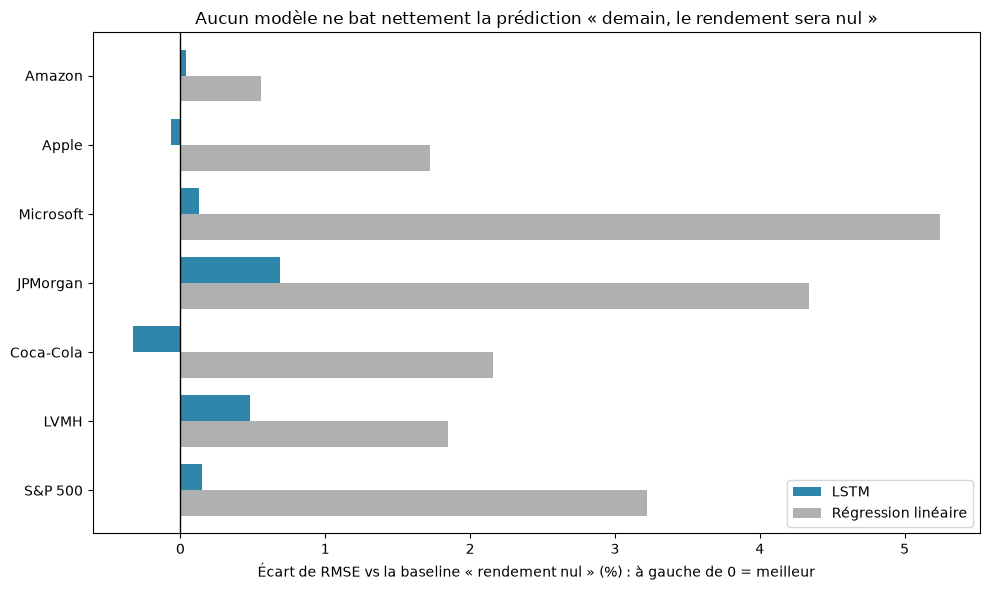

In [68]:
import os

names = {"AMZN": "Amazon", "AAPL": "Apple", "MSFT": "Microsoft", "JPM": "JPMorgan",
         "KO": "Coca-Cola", "MC.PA": "LVMH", "^GSPC": "S&P 500"}

ecarts = pd.DataFrame({
    "LSTM": results_all["LSTM vs zéro (%)"],
    "Régression linéaire": 100 * (results_all["RMSE linéaire"] / results_all["RMSE zéro"] - 1),
}).rename(index=names)

ax = ecarts.plot.barh(figsize=(10, 6), color=["#2E86AB", "#B0B0B0"], width=0.75)
ax.axvline(0, color="black", linewidth=1)
ax.invert_yaxis()
ax.set_xlabel("Écart de RMSE vs la baseline « rendement nul » (%) : à gauche de 0 = meilleur")
ax.set_ylabel("")
ax.set_title("Aucun modèle ne bat nettement la prédiction « demain, le rendement sera nul »")
ax.legend(loc="lower right")
plt.tight_layout()

os.makedirs("reports/figures", exist_ok=True)
plt.savefig("reports/figures/benchmark_ecarts.png", dpi=150, bbox_inches="tight")
plt.show()